# 1. Title

**Prepared for:** Mohammed (MM)  
**Dataset:** Titanic passenger records (Data Science Dojo)

This project builds a reusable Python workflow for loading, cleaning, and exploring Titanic passenger data. It compares survival across passenger class, recorded sex, and family status, then examines how missing-age handling affects descriptive conclusions.

**Authorship disclosure:** This is an AI-assisted implementation prepared with Codex; Mohammed must review, understand, and adapt the work before submission under the course authorship rules.

## 2. Setup
Use deterministic operations and a fixed random seed. Run all cells from this directory; no network download is required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

np.random.seed(42)
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
print("Setup complete: NumPy, pandas, Matplotlib, Seaborn and IPython loaded; random seed = 42.")


Setup complete: NumPy, pandas, Matplotlib, Seaborn and IPython loaded; random seed = 42.


## 3. Ingestion
Load the supplied CSV unchanged. Record its initial shape, missing values, duplicate count, and data types before cleaning.

In [2]:
df = pd.read_csv("titanic.csv")
display(df.head())
display(df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().rename("Missing values").to_frame())
display(df.dtypes.astype(str).rename("Data type").to_frame())
print("Numeric columns:", len(df.select_dtypes(include="number").columns))
print("Text columns:", len(df.select_dtypes(exclude="number").columns))
assert df.shape == (891, 12)
assert df["PassengerId"].is_unique
assert df["Survived"].isin([0, 1]).all()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


(891, 12)

Duplicate rows: 0


,Missing values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


,Data type
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


Numeric columns: 7
Text columns: 5


## 4. Cleaning functions
Keep all passengers. Fill missing ages with the overall observed median (robust to extreme ages), and preserve missingness in an `AgeWasMissing` flag. Mark missing Cabin and Embarked as `Unknown`; this is a missingness label, not an inferred cabin or port. Derive family size and alone status without modifying the raw frame. Fare is not imputed because it has no missing values.

In [3]:
def handle_missing_values(frame):
    """Copy the frame, flag and median-fill Age, and label absent Cabin/Embarked."""
    cleaned = frame.copy(deep=True)
    cleaned["AgeWasMissing"] = cleaned["Age"].isna()
    age_median = cleaned["Age"].median()
    if pd.isna(age_median):
        raise ValueError("Age requires at least one observed value for median imputation.")
    cleaned["Age"] = cleaned["Age"].fillna(age_median)
    for column in ["Cabin", "Embarked"]:
        cleaned[column] = cleaned[column].fillna("Unknown")
    return cleaned


def derive_family_features(frame):
    """Copy the frame and derive FamilySize and boolean IsAlone from SibSp/Parch."""
    cleaned = frame.copy(deep=True)
    cleaned["FamilySize"] = cleaned["SibSp"] + cleaned["Parch"] + 1
    cleaned["IsAlone"] = cleaned["FamilySize"].eq(1)
    return cleaned


cleaned_df = derive_family_features(handle_missing_values(df))
print("Observed median Age:", df["Age"].median())
display(cleaned_df.isna().sum().rename("Missing after cleaning").to_frame())
display(cleaned_df[["Age", "AgeWasMissing", "Cabin", "Embarked", "FamilySize", "IsAlone"]].head())
assert len(cleaned_df) == len(df)
assert cleaned_df.isna().sum().sum() == 0
assert cleaned_df["AgeWasMissing"].sum() == 177
assert cleaned_df["IsAlone"].equals(cleaned_df["FamilySize"].eq(1))
assert df["Age"].isna().sum() == 177  # raw input stays unchanged


Observed median Age: 28.0


,Missing after cleaning
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


,Age,AgeWasMissing,Cabin,Embarked,FamilySize,IsAlone
0,22.0,False,Unknown,S,2,False
1,38.0,False,C85,C,2,False
2,26.0,False,Unknown,S,1,True
3,35.0,False,C123,S,2,False
4,35.0,False,Unknown,S,1,True


## 5. Exploratory analysis function
Report group sizes alongside survival percentages. Associations are descriptive and do not establish causal effects. Compare three age treatments using fixed under-18 and 18-plus groups; class and sex survival rates remain unchanged when only Age is filled and all rows are retained.

In [4]:
def survival_by_group(frame, column):
    """Return passenger counts, survivor counts and survival percent by a column."""
    grouped = frame.groupby(column, dropna=False, observed=True)["Survived"].agg(
        Passengers="size", Survivors="sum", SurvivalRate="mean"
    )
    grouped["SurvivalPercent"] = 100 * grouped["SurvivalRate"]
    return grouped


display(cleaned_df.describe())
for column in ["Pclass", "Sex", "IsAlone"]:
    print("Survival grouped by", column)
    display(survival_by_group(cleaned_df, column).round(3))
print("Overall survival percent:", round(100 * cleaned_df["Survived"].mean(), 3))
print("Age missingness by passenger class (%)")
display((100 * df.assign(AgeMissing=df["Age"].isna()).groupby("Pclass")["AgeMissing"].mean()).to_frame("AgeMissingPercent"))

group_age = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))
treatments = {
    "Observed ages only": df.loc[df["Age"].notna()].copy(),
    "Overall median": cleaned_df.copy(),
    "Class/sex median": df.assign(Age=group_age),
}
sensitivity_tables = []
for method, frame in treatments.items():
    frame = frame.assign(AgeGroup=np.where(frame["Age"] < 18, "Under 18", "18 and above"))
    table = survival_by_group(frame, "AgeGroup").reset_index()
    table.insert(0, "Method", method)
    sensitivity_tables.append(table)
sensitivity = pd.concat(sensitivity_tables, ignore_index=True)
display(sensitivity.round(3))
print("Mean Age by outcome, before versus after filling")
display(pd.DataFrame({"Observed": df.groupby("Survived")["Age"].mean(),
                      "Median filled": cleaned_df.groupby("Survived")["Age"].mean(),
                      "Class/sex median": df.assign(Age=group_age).groupby("Survived")["Age"].mean()}))


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208,1.904602
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429,1.613459
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,1.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,1.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,1.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,2.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,11.000000


Survival grouped by Pclass


,Passengers,Survivors,SurvivalRate,SurvivalPercent
Pclass,,,,
1,216,136,0.630,62.963
2,184,87,0.473,47.283
3,491,119,0.242,24.236


Survival grouped by Sex


,Passengers,Survivors,SurvivalRate,SurvivalPercent
Sex,,,,
female,314,233,0.742,74.204
male,577,109,0.189,18.891


...

Overall survival percent: 38.384
Age missingness by passenger class (%)


,AgeMissingPercent
Pclass,
1,13.888889
2,5.978261
3,27.698574


,Method,AgeGroup,Passengers,Survivors,SurvivalRate,SurvivalPercent
0,Observed ages only,18 and above,601,229,0.381,38.103
1,Observed ages only,Under 18,113,61,0.540,53.982
2,Overall median,18 and above,778,281,0.361,36.118
3,Overall median,Under 18,113,61,0.540,53.982
4,Class/sex median,18 and above,778,281,0.361,36.118
5,Class/sex median,Under 18,113,61,0.540,53.982


Mean Age by outcome, before versus after filling


,Observed,Median filled,Class/sex median
Survived,,,
0,30.626179,30.028233,29.737705
1,28.343690,28.291433,28.108684


## 6. Visualizations
Figures 1 and 2 use all 891 rows. Figure 3 uses observed ages only (714 passengers) so the artificial spike from 177 median-filled ages is not presented as an observed age pattern. The sensitivity table above evaluates the filled data separately.

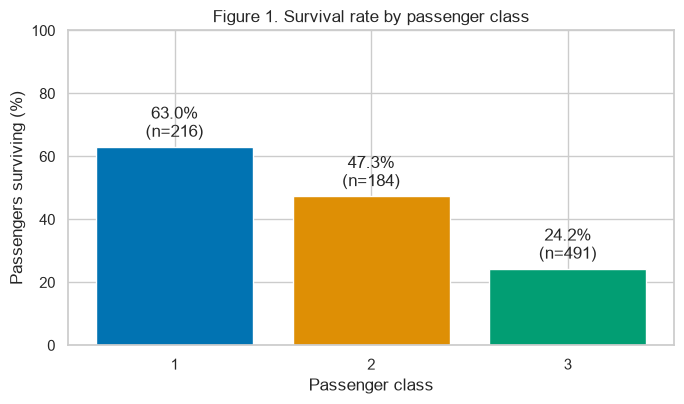

In [5]:
rates = survival_by_group(cleaned_df, "Pclass")
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(rates.index.astype(str), rates["SurvivalPercent"], color=sns.color_palette("colorblind", len(rates)))
ax.bar_label(bars, labels=[f"{p:.1f}%\n(n={n})" for p, n in zip(rates["SurvivalPercent"], rates["Passengers"])], padding=4)
ax.set(title="Figure 1. Survival rate by passenger class", xlabel="Passenger class", ylabel="Passengers surviving (%)", ylim=(0, 100))
fig.tight_layout()
fig.savefig(FIGURES / "figure_1_class.png", dpi=160)
plt.show()
plt.close(fig)


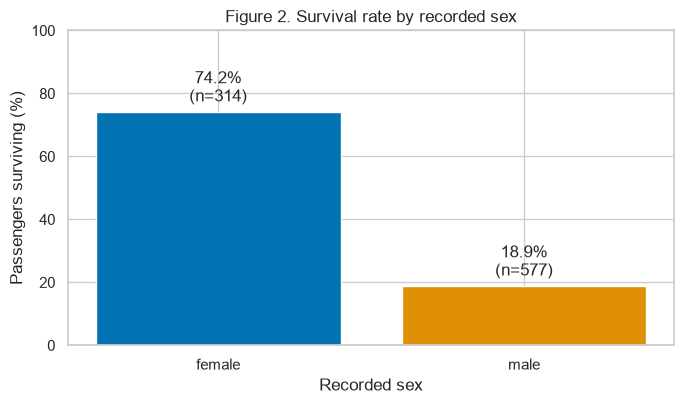

In [6]:
rates = survival_by_group(cleaned_df, "Sex")
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(rates.index.astype(str), rates["SurvivalPercent"], color=sns.color_palette("colorblind", len(rates)))
ax.bar_label(bars, labels=[f"{p:.1f}%\n(n={n})" for p, n in zip(rates["SurvivalPercent"], rates["Passengers"])], padding=4)
ax.set(title="Figure 2. Survival rate by recorded sex", xlabel="Recorded sex", ylabel="Passengers surviving (%)", ylim=(0, 100))
fig.tight_layout()
fig.savefig(FIGURES / "figure_2_sex.png", dpi=160)
plt.show()
plt.close(fig)


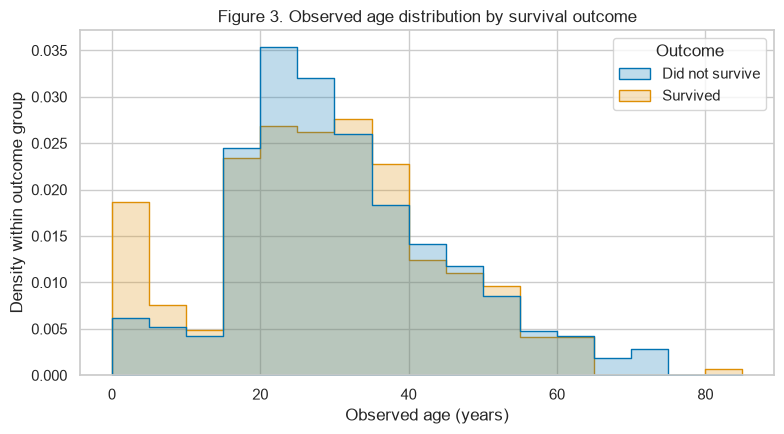

In [7]:
observed_ages = df.loc[df["Age"].notna()].copy()
observed_ages["Outcome"] = observed_ages["Survived"].map({0: "Did not survive", 1: "Survived"})
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=observed_ages, x="Age", hue="Outcome", bins=np.arange(0, 86, 5),
             stat="density", common_norm=False, element="step", alpha=0.25, ax=ax)
ax.set(title="Figure 3. Observed age distribution by survival outcome",
       xlabel="Observed age (years)", ylabel="Density within outcome group")
fig.tight_layout()
fig.savefig(FIGURES / "figure_3_age.png", dpi=160)
plt.show()
plt.close(fig)


## 7. Summary

Of 891 passengers, 342 survived (38.4%). First-class passengers had a 63.0% survival rate, compared with 47.3% in second class and 24.2% in third class (Figure 1). Recorded female passengers had a 74.2% survival rate compared with 18.9% for recorded male passengers (Figure 2). Passengers traveling alone had a 30.4% survival rate, compared with 50.6% among those with recorded family aboard; these are associations that may overlap with class, age, and sex.

Figure 3 shows overlapping observed-age distributions, with many passengers in young adulthood; it does not imply age alone explains survival. Missing ages affect 177 passengers (19.9%), and the sensitivity table shows adult survival of 38.1% with observed ages versus 36.1% after either fill. The two fill methods give identical under-18 group rates here, but different mean ages by outcome; different methods do not necessarily change every statistic. Median imputation preserves rows but compresses age variation and does not resolve the cause of missingness. The observed-age figure avoids treating filled values as measurements, but its 714-passenger subset can still be selective.

Cabin is missing for 687 passengers (77.1%); Unknown preserves that absence without inventing cabin identities. Embarked has two missing values. This historical dataset is not a representative sample of present-day populations, the recorded sex field is limited to its original categories, and grouped rates are not causal conclusions or evidence for modern allocation decisions. A future predictive pipeline would split data before fitting preprocessing and evaluate performance and error rates across groups.
